# Homework 8.1 - Task 3

## Score Field and Mode Merging

The mixture contains two latent Gaussian components at every time before the final collapse.

However, two mixture components do not necessarily produce two visible density maxima.

This notebook compares:

- the exact score field;
- the number of visible density peaks;
- the analytic threshold at which the two peaks merge.

## 1. Analytic bimodality condition

For the symmetric equal-weight mixture

$$
\frac{1}{2}N(-m,v)
+
\frac{1}{2}N(m,v),
$$

the center $x=0$ changes from a local minimum to a local maximum when

$$
m^2=v.
$$

Therefore the density has two distinct peaks when

$$
m>\sqrt{v}.
$$

In our schedule,

$$
m(t)=2\alpha(t)
$$

and

$$
v(t)=1-q\alpha(t)^2.
$$

The merge time satisfies

$$
4\alpha(t)^2
=
1-q\alpha(t)^2.
$$

Hence

$$
\alpha(t)^2
=
\frac{1}{4+q}.
$$

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(config["a"])
Q = float(config["q"])

In [2]:
def alpha(t):
    return np.cos(
        0.5
        * np.pi
        * np.asarray(
            t,
            dtype=float,
        )
    )


def variance(t):
    a = alpha(t)
    return (
        1.0
        - Q * a**2
    )


def normal_density(
    x,
    mean,
    var,
):
    return (
        np.exp(
            -0.5
            * (x - mean)**2
            / var
        )
        / np.sqrt(
            2.0
            * np.pi
            * var
        )
    )


def mixture_density(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        0.5
        * normal_density(
            x,
            -m,
            v,
        )
        + 0.5
        * normal_density(
            x,
            m,
            v,
        )
    )


def exact_score(
    x,
    t,
):
    m = A * alpha(t)
    v = variance(t)

    return (
        m
        * np.tanh(
            m * x / v
        )
        - x
    ) / v


alpha_merge = (
    1.0
    / np.sqrt(
        A**2 + Q
    )
)

t_merge = (
    2.0
    / np.pi
    * np.arccos(
        alpha_merge
    )
)

print("Analytic merge time:", t_merge)

Analytic merge time: 0.7028228908285569


## 2. Numerically count the density maxima

A dense grid and peak finder are used as an independent numerical check of the analytic criterion.

At the exact merge threshold, the center is a degenerate flat maximum: the second derivative vanishes. Floating-point roundoff can make a generic peak finder split that one flat maximum into two grid points immediately to the left and right of zero. To avoid reporting that numerical artifact as physical bimodality, the code first checks whether the center agrees with the global grid maximum to a tight numerical tolerance. If it does, the numerical result is recorded as one central maximum.


In [3]:
x_grid = np.linspace(
    -5.0,
    5.0,
    100_001,
)

check_times = [
    0.0,
    0.25,
    0.50,
    0.65,
    float(t_merge),
    0.75,
    0.90,
    0.99,
    1.0,
]

rows = []

for t in check_times:
    density = mixture_density(
        x_grid,
        t,
    )

    peaks, properties = find_peaks(
        density,
        prominence=1e-8,
    )

    center_index = len(x_grid) // 2
    maximum_density = float(np.max(density))
    center_density = float(density[center_index])

    center_matches_global_max = (
        maximum_density - center_density
        <= 1e-12 * max(1.0, maximum_density)
    )

    if center_matches_global_max:
        numerical_peak_count = 1
        numerical_peak_locations = "0.000000"
    else:
        numerical_peak_count = int(len(peaks))
        numerical_peak_locations = "|".join(
            f"{x_grid[index]:.6f}"
            for index in peaks
        )

    analytic_two_modes = (
        A * alpha(t)
        > np.sqrt(
            variance(t)
        )
        + 1e-12
    )

    rows.append({
        "t": t,
        "mean_magnitude_m": float(
            A * alpha(t)
        ),
        "component_sigma": float(
            np.sqrt(
                variance(t)
            )
        ),
        "analytic_two_distinct_peaks": bool(
            analytic_two_modes
        ),
        "numerical_peak_count": numerical_peak_count,
        "numerical_peak_locations": numerical_peak_locations,
    })


mode_table = pd.DataFrame(
    rows
)

mode_table_path = (
    DATA_DIR
    / "task3_mode_count_validation.csv"
)

mode_table.to_csv(
    mode_table_path,
    index=False,
)

print(
    mode_table.to_string(
        index=False
    )
)


       t  mean_magnitude_m  component_sigma  analytic_two_distinct_peaks  numerical_peak_count numerical_peak_locations
0.000000      2.000000e+00         0.250000                         True                     2       -2.000000|2.000000
0.250000      1.847759e+00         0.446983                         True                     2       -1.847800|1.847800
0.500000      1.414214e+00         0.728869                         True                     2       -1.412700|1.412700
0.650000      1.044997e+00         0.862588                         True                     2       -0.883900|0.883900
0.702823      9.000703e-01         0.900070                        False                     1                 0.000000
0.750000      7.653669e-01         0.928820                        False                     1                 0.000000
0.900000      3.128689e-01         0.988462                        False                     1                 0.000000
0.990000      3.141463e-02         0.999

## 3. Score curves around the merge time

The zeros of the score are the stationary points of the density.

Before merging, the score has three zeros:

- a left maximum;
- the central minimum;
- a right maximum.

After merging, only the central maximum remains.

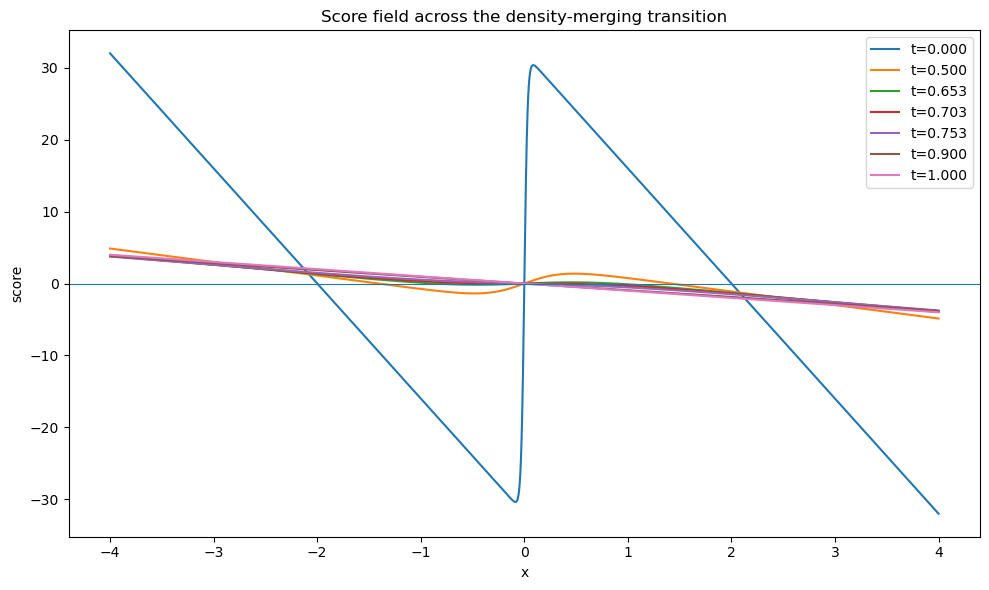

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task3_score_near_merge.png


In [4]:
plot_times = [
    0.0,
    0.50,
    max(
        0.0,
        t_merge - 0.05,
    ),
    t_merge,
    min(
        1.0,
        t_merge + 0.05,
    ),
    0.90,
    1.0,
]

x_plot = np.linspace(
    -4.0,
    4.0,
    4000,
)

plt.figure(
    figsize=(10, 6)
)

for t in plot_times:
    plt.plot(
        x_plot,
        exact_score(
            x_plot,
            t,
        ),
        label=f"t={t:.3f}",
    )

plt.axhline(
    0.0,
    linewidth=0.8,
)

plt.xlabel("x")
plt.ylabel("score")
plt.title(
    "Score field across the density-merging transition"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task3_score_near_merge.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

## 4. Direction map

A positive score points toward increasing density in the positive $x$ direction.

A negative score points toward increasing density in the negative $x$ direction.

The sign map below shows how the attraction regions change as the two visible peaks merge.

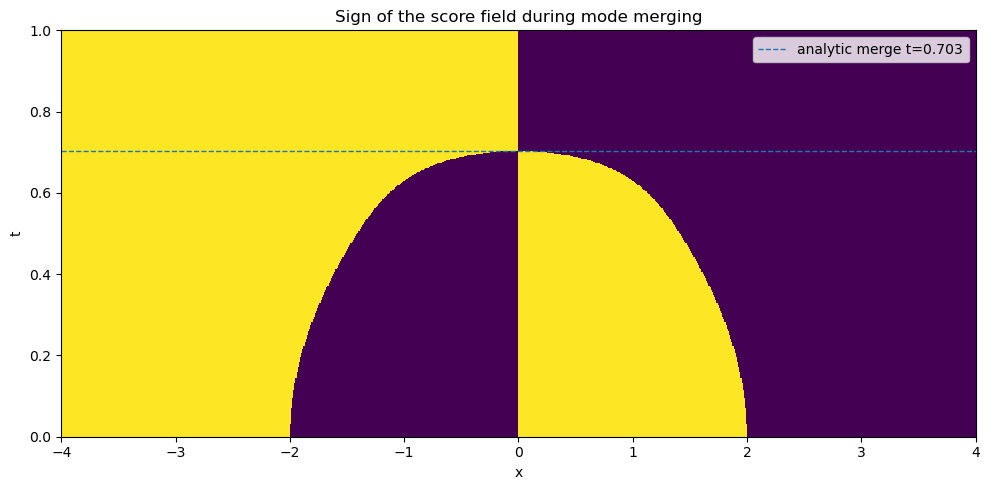

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task3_score_direction_map.png


In [5]:
t_values = np.linspace(
    0.0,
    1.0,
    500,
)

x_values = np.linspace(
    -4.0,
    4.0,
    800,
)

score_grid = np.empty(
    (
        len(t_values),
        len(x_values),
    ),
    dtype=float,
)

for i, t in enumerate(
    t_values
):
    score_grid[i] = exact_score(
        x_values,
        t,
    )

sign_grid = np.sign(
    score_grid
)

plt.figure(
    figsize=(10, 5)
)

plt.imshow(
    sign_grid,
    aspect="auto",
    origin="lower",
    extent=[
        x_values[0],
        x_values[-1],
        t_values[0],
        t_values[-1],
    ],
    interpolation="nearest",
)

plt.axhline(
    t_merge,
    linestyle="--",
    linewidth=1.0,
    label=f"analytic merge t={t_merge:.3f}",
)

plt.xlabel("x")
plt.ylabel("t")
plt.title(
    "Sign of the score field during mode merging"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task3_score_direction_map.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 3 Conclusion

The two visible density peaks merge at the analytic threshold where

$$
m(t)=\sigma(t).
$$

For the chosen schedule, the merge occurs at approximately $t=0.702823$. The corrected numerical peak count agrees with the analytic result, including the degenerate equality case, where the density has one flat central maximum rather than two distinct maxima.

The latent mixture still has two component labels before the final endpoint even after the density has become unimodal. Therefore these statements are not equivalent:

- the model has two mixture components;
- the density visibly has two peaks.

Task 4 derives the reverse probability-flow dynamics and checks the drift sign independently.
